# Test Code Execution with Power Profiling

In [7]:
# Import modules
import lassi.code_manager
import lassi.llm_methods
from lassi.get_power import report_gpu_memory
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.code_manager
%aimport lassi.llm_methods
%aimport lassi.get_power
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary

prompts = PromptDictionary()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
report_gpu_memory()


----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 49.78 W, P0



In [2]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


In [1]:
!nvidia-smi -q


==============NVSMI LOG==============

Timestamp                                 : Thu Apr  3 06:18:29 2025
Driver Version                            : 560.35.05
CUDA Version                              : 12.6

Attached GPUs                             : 1
GPU 00000000:24:00.0
    Product Name                          : NVIDIA A100 80GB PCIe
    Product Brand                         : NVIDIA
    Product Architecture                  : Ampere
    Display Mode                          : Enabled
    Display Active                        : Disabled
    Persistence Mode                      : Disabled
    Addressing Mode                       : None
    MIG Mode
        Current                           : Disabled
        Pending                           : Disabled
    Accounting Mode                       : Disabled
    Accounting Mode Buffer Size           : 4000
    Driver Model
        Current                           : N/A
        Pending                           : N/A
    Serial 

In [14]:
!nvidia-smi --query-gpu=pci.bus_id,pci.device_id,pci.domain,pci.bus --format=csv

pci.bus_id, pci.device_id, pci.domain, pci.bus
00000000:24:00.0, 0x20B510DE, 0x0000, 0x24


In [9]:
# Code to test
folder = "test_codes/all-pairs-distance/"
code_filename = "all-pairs-distance-cuda_main_ee_refactorcode_CUDA_exp_t14.3-idlecorr_pipelineV2_o3mini_allpairs_argo_ee_hecb_selfcontext_04-03-2025_t05_31_23_v0-baseLLM.cu"
exe_input_parameters = ["10000"]

with open(folder + "/" + code_filename, 'r') as file:
    refactored_code = file.read()
file.close()

# Parameters
power_measure = True

source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100

In [5]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main_ee_refactorcode_CUDA_exp_t14.3-idlecorr_pipelineV2_o3mini_allpairs_argo_ee_hecb_selfcontext_04-03-2025_t05_31_23_v0-baseLLM.cu', '-o', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main_ee_refactorcode_CUDA_exp_t14.3-idlecorr_pipelineV2_o3mini_allpairs_argo_ee_hecb_selfcontext_04-03-2025_t05_31_23_v0-baseLLM']

Compilation of code successful!



Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 49.31 W, P0



Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]

Working directory: test_codes/all-pairs-distance
Execute command: ['./all-pairs-distance-cuda_main_ee_refactorcode_CUDA_exp_t14.3-idlecorr_pipelineV2_o3mini_allpairs_argo_ee_hecb_selfcontext_04-03-2025_t05_31_23_v0-baseLLM', '10000']



CPU time: 119029 (us)
Kernel k1 average execution time: 123.973801 (us)
Kernel k1 verification: PASS
Kernel k2 average execution time: 132.843506 (us)
Kernel k2 verification: PASS
Kernel k3 average execution time: 123.785500 (us)
Kernel k3 verification: PASS
GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


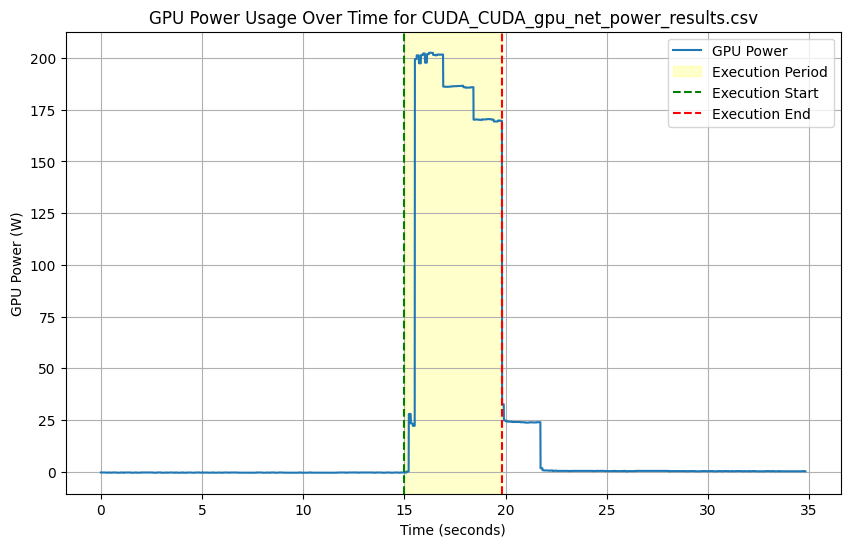

Start time: 15.001 -- End time: 19.831
Total GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000224 kWh
  0.2241 Wh
  806.93 J
Average GPU power: 167.06 W
 with sample standard deviation: 54.77
Total Energy During Exe Runtime:   806.93 J
Code execution duration: 4.83 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 49.98 W, P0



In [15]:
execute_result, exe_output, total_energy_joules, ave_power, std_power, duration, metrics_results_string = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

In [ ]:
# Measure system idle power
"""
print("Measure system idle power...")
idle_energy_joules, idle_ave_power = lassi.get_power.idlepower(duration)
actual_energy = total_energy_joules - idle_energy_joules
actual_ave_power = ave_power - idle_ave_power
print(color.BOLD + color.BLUE + "\nActual measured values during runtime for " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{actual_ave_power:.2f} W" + color.END)
print("Total Energy During Exe Runtime: " + color.BOLD + f"{actual_energy:.2f} J" + color.END)
"""

# Code Validation with LLM-as-a-Judge

In [16]:
# Run source code
# Call llm-as-a-judge method
# Source Code to test
folder = "test_codes/all-pairs-distance/"
code_filename = "all-pairs-distance-cuda_main.cu"
with open(folder + "/" + code_filename, 'r') as file:
    source_code = file.read()
file.close()

In [17]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main.cu', '-o', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main']

Compilation of code successful!



Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 49.60 W, P0



Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]

Working directory: test_codes/all-pairs-distance
Execute command: ['./all-pairs-distance-cuda_main', '10000']



CPU time: 119926.000000 (us)
Average kernel execution time: 167.078598 (us)
PASS
Average kernel execution time: 175.190308 (us)
PASS
Average kernel execution time: 169.313202 (us)
PASS
GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


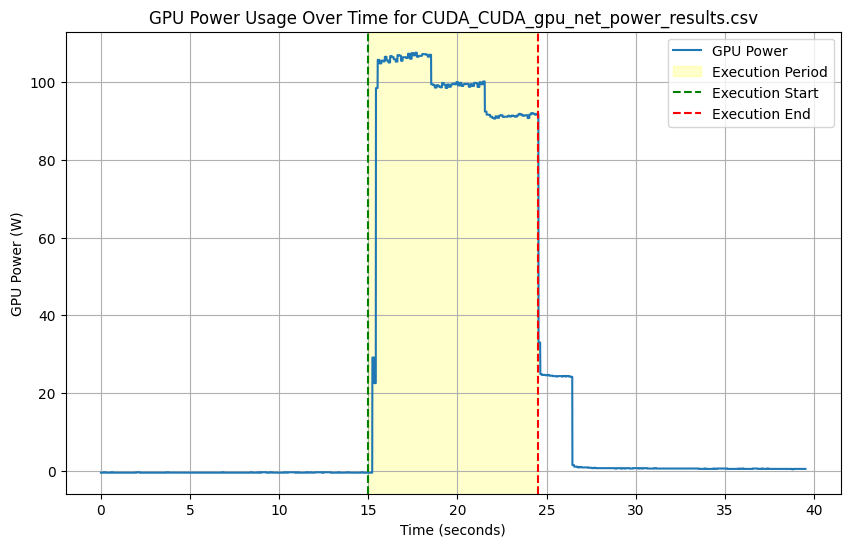

Start time: 15.001 -- End time: 24.523
Total GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000252 kWh
  0.2516 Wh
  905.87 J
Average GPU power: 95.15 W
 with sample standard deviation: 19.10
Total Energy During Exe Runtime:   905.87 J
Code execution duration: 9.52 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.47 W, P0



In [18]:
execute_result_source, exe_output_source, total_energy_joules_source, ave_power_source, std_power, duration_source, metrics_results_string_source = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

In [ ]:
# Save source code results into a local JSON file for quick loading

In [19]:
llm_source = "argo"
model_judge = "gpto3mini"
num_ctx = 20000
general_system_prompt = prompts.get_system_prompt("general_system_ee")
input_content_llmjudge_dict = {
    "source_code": source_code,
    "source_stdout": exe_output_source,
    "source_metrics": metrics_results_string_source,
    "refactored_code": refactored_code,
    "refactored_stdout": exe_output,
    "refactored_metrics": metrics_results_string,
} 
display_response = True
verifyprompt = False

# Call LLM-as-a-judge to review SOURCE CODE and REFACTORED CODE to evaluate if likely valid
valid_code_flag = lassi.llm_methods.llm_judge(
    llm_source,
    model_judge,
    num_ctx,
    general_system_prompt,
    input_content_llmjudge_dict,
    display_response,
    verifyprompt
)
print(f"\nResult: {valid_code_flag}")



--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



The refactored code retains the original functionality. It still implements the exact same computations on the data (both on the CPU and on the GPU), uses the same kernels (k1, k2, k3) with the same logic, and carries out identical comparisons of CPU versus GPU results to issue “PASS” or “FAIL”. Although the refactored version uses cudaMemset to zero data on the device (instead of bzero divided between the host and device), allocates pinned host memory instead of standard malloc, and replaces gettimeofday timing with CUDA events and C++ chrono, these are optimizations meant to reduce power/energy consumption while not changing the fundamental behavior of the code. The printed output format remains nearly identical—with microsecond timings for CPU and kernel execution times and PASS messages for verification—which meets the requirement that the layout and content of the standard output be functionally equivalent. 

Therefore, the REFACTORED CODE is functionally equivalent.

VALID



----- END LLM RESPONSE -----


Result: VALID
